In [226]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [227]:
vr_data_collision = pd.read_csv("perception_times (2).csv")
vr_data_collision.head(5)

,Object,Relative Time (s),Synced-Time,Exact Timestamp,Collision Time
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,5.611
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,6.629
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,6.431
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,5.186
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,6.633


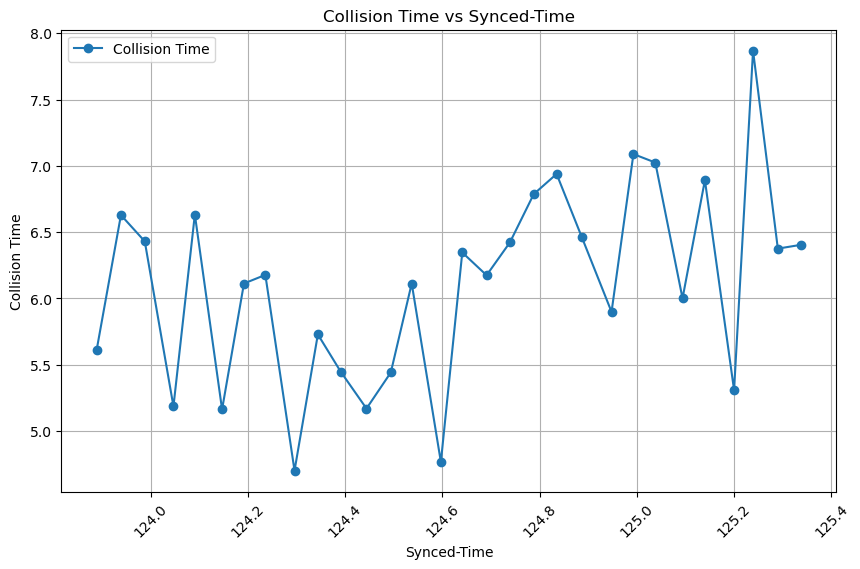

In [228]:
# Plot data
plt.figure(figsize=(10, 6))
plt.plot(vr_data_collision['Synced-Time'][0:30], vr_data_collision['Collision Time'][0:30], marker='o', linestyle='-', label='Collision Time')
plt.xlabel('Synced-Time')
plt.ylabel('Collision Time')
plt.title('Collision Time vs Synced-Time')
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.show()

# Find groups of threats

In [229]:
# Calculate the time difference to the next row
vr_data_collision['TIME_Difference'] = vr_data_collision['Relative Time (s)'].diff(1).abs()

# Fill the last row with zero (as it has no next row)
vr_data_collision['TIME_Difference'] =  vr_data_collision['TIME_Difference'].fillna(0)


In [230]:
vr_data_collision

,Object,Relative Time (s),Synced-Time,Exact Timestamp,Collision Time,TIME_Difference
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,5.611,0.000
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,6.629,0.050
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,6.431,0.049
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,5.186,0.059
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,6.633,0.044
...,...,...,...,...,...,...
4205,roller_v2,5011.942,5135.831,2025.01.07-01.49.52:068000,2.449,0.046
4206,roller_v2,5011.989,5135.878,2025.01.07-01.49.52:115000,3.323,0.047
4207,roller_v2,5012.040,5135.929,2025.01.07-01.49.52:166000,4.203,0.051
4208,roller_v2,5012.090,5135.979,2025.01.07-01.49.52:216000,8.839,0.050


In [231]:
# Identify where the difference is greater than 5
vr_data_collision['Group'] = (vr_data_collision['TIME_Difference'] > 5).cumsum()

In [232]:
vr_data_collision

,Object,Relative Time (s),Synced-Time,Exact Timestamp,Collision Time,TIME_Difference,Group
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,5.611,0.000,0
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,6.629,0.050,0
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,6.431,0.049,0
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,5.186,0.059,0
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,6.633,0.044,0
...,...,...,...,...,...,...,...
4205,roller_v2,5011.942,5135.831,2025.01.07-01.49.52:068000,2.449,0.046,158
4206,roller_v2,5011.989,5135.878,2025.01.07-01.49.52:115000,3.323,0.047,158
4207,roller_v2,5012.040,5135.929,2025.01.07-01.49.52:166000,4.203,0.051,158
4208,roller_v2,5012.090,5135.979,2025.01.07-01.49.52:216000,8.839,0.050,158


Now we have a group column that shows id of threat next we will find the response point of each threat

In [233]:
# Group by 'Group' and find the row index with minimum 'time-to-collision'
representative_rows = vr_data_collision.loc[vr_data_collision.groupby('Group')['Collision Time'].idxmin()]
representative_rows

,Object,Relative Time (s),Synced-Time,Exact Timestamp,Collision Time,TIME_Difference,Group
50,Lifter,2.505,126.394,2025.01.07-00.26.22:631000,4.470,0.060,0
110,Lifter,163.960,287.849,2025.01.07-00.29.04:086000,3.314,0.057,1
147,Lifter,174.750,298.639,2025.01.07-00.29.14:876000,27.423,0.056,2
149,Lifter,614.568,738.457,2025.01.07-00.36.34:694000,2.501,439.773,3
155,Lifter,683.022,806.911,2025.01.07-00.37.43:148000,2.862,68.206,4
...,...,...,...,...,...,...,...
4134,roller_v2,4494.372,4618.261,2025.01.07-01.41.14:498000,2.700,0.056,154
4148,roller_v2,4655.318,4779.207,2025.01.07-01.43.55:444000,2.753,0.065,155
4159,roller_v2,4696.786,4820.675,2025.01.07-01.44.36:912000,1.906,40.979,156
4166,roller_v2,4995.798,5119.687,2025.01.07-01.49.35:924000,4.016,298.716,157


In [234]:
# Calculate the time difference between the representative point and the first row of each group
representative_rows['Response_Time'] = (
    representative_rows['Relative Time (s)'] - vr_data_collision.groupby('Group')['Relative Time (s)'].transform('first')
)

# # Convert time difference to  absolute seconds (in case of any negative values)
# representative_rows['Response_Time'] =  representative_rows['Time_Distance']

representative_rows

,Object,Relative Time (s),Synced-Time,Exact Timestamp,Collision Time,TIME_Difference,Group,Response_Time
50,Lifter,2.505,126.394,2025.01.07-00.26.22:631000,4.470,0.060,0,2.505
110,Lifter,163.960,287.849,2025.01.07-00.29.04:086000,3.314,0.057,1,0.453
147,Lifter,174.750,298.639,2025.01.07-00.29.14:876000,27.423,0.056,2,0.453
149,Lifter,614.568,738.457,2025.01.07-00.36.34:694000,2.501,439.773,3,0.000
155,Lifter,683.022,806.911,2025.01.07-00.37.43:148000,2.862,68.206,4,0.000
...,...,...,...,...,...,...,...,...
4134,roller_v2,4494.372,4618.261,2025.01.07-01.41.14:498000,2.700,0.056,154,0.205
4148,roller_v2,4655.318,4779.207,2025.01.07-01.43.55:444000,2.753,0.065,155,0.261
4159,roller_v2,4696.786,4820.675,2025.01.07-01.44.36:912000,1.906,40.979,156,0.000
4166,roller_v2,4995.798,5119.687,2025.01.07-01.49.35:924000,4.016,298.716,157,0.000


# Rescue :)


In [235]:
vr_data_collision

,Object,Relative Time (s),Synced-Time,Exact Timestamp,Collision Time,TIME_Difference,Group
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,5.611,0.000,0
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,6.629,0.050,0
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,6.431,0.049,0
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,5.186,0.059,0
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,6.633,0.044,0
...,...,...,...,...,...,...,...
4205,roller_v2,5011.942,5135.831,2025.01.07-01.49.52:068000,2.449,0.046,158
4206,roller_v2,5011.989,5135.878,2025.01.07-01.49.52:115000,3.323,0.047,158
4207,roller_v2,5012.040,5135.929,2025.01.07-01.49.52:166000,4.203,0.051,158
4208,roller_v2,5012.090,5135.979,2025.01.07-01.49.52:216000,8.839,0.050,158


In [236]:
WINDOW_SIZE = 1

In [237]:
vr_data_collision['Start_Time'] = vr_data_collision.groupby('Group')['Relative Time (s)'].transform('first')

# Filter the DataFrame to include only rows within the window size
vr_data_collision_windowed = vr_data_collision[
    (vr_data_collision['Relative Time (s)'] >= vr_data_collision['Start_Time']) &
    (vr_data_collision['Relative Time (s)'] <= vr_data_collision['Start_Time'] + WINDOW_SIZE)
]
vr_data_collision_windowed

,Object,Relative Time (s),Synced-Time,Exact Timestamp,Collision Time,TIME_Difference,Group,Start_Time
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,5.611,0.000,0,0.000
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,6.629,0.050,0,0.000
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,6.431,0.049,0,0.000
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,5.186,0.059,0,0.000
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,6.633,0.044,0,0.000
...,...,...,...,...,...,...,...,...
4183,roller_v2,5010.841,5134.730,2025.01.07-01.49.50:967000,1.365,0.052,158,5010.041
4184,roller_v2,5010.886,5134.775,2025.01.07-01.49.51:012000,1.605,0.045,158,5010.041
4185,roller_v2,5010.937,5134.826,2025.01.07-01.49.51:063000,1.415,0.051,158,5010.041
4186,roller_v2,5010.993,5134.882,2025.01.07-01.49.51:119000,1.257,0.056,158,5010.041


In [238]:
merged_df = pd.merge(vr_data_collision_windowed, representative_rows[['Group', 'Collision Time', 'Response_Time']],
                     on=['Group'], how='left')
merged_df.drop(columns= 'Collision Time_x',inplace=True)
merged_df['Collision Time'] = merged_df['Collision Time_y']
merged_df

,Object,Relative Time (s),Synced-Time,Exact Timestamp,TIME_Difference,Group,Start_Time,Collision Time_y,Response_Time,Collision Time
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,0.000,0,0.000,4.470,2.505,4.470
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,0.050,0,0.000,4.470,2.505,4.470
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,0.049,0,0.000,4.470,2.505,4.470
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,0.059,0,0.000,4.470,2.505,4.470
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,0.044,0,0.000,4.470,2.505,4.470
...,...,...,...,...,...,...,...,...,...,...
2276,roller_v2,5010.841,5134.730,2025.01.07-01.49.50:967000,0.052,158,5010.041,1.079,0.302,1.079
2277,roller_v2,5010.886,5134.775,2025.01.07-01.49.51:012000,0.045,158,5010.041,1.079,0.302,1.079
2278,roller_v2,5010.937,5134.826,2025.01.07-01.49.51:063000,0.051,158,5010.041,1.079,0.302,1.079
2279,roller_v2,5010.993,5134.882,2025.01.07-01.49.51:119000,0.056,158,5010.041,1.079,0.302,1.079


In [239]:
merged_df.columns

Index(['Object', 'Relative Time (s)', 'Synced-Time', 'Exact Timestamp',
       'TIME_Difference', 'Group', 'Start_Time', 'Collision Time_y',
       'Response_Time', 'Collision Time'],
      dtype='object')

# Lets find the time of first point

In [240]:
# representative_rows['Start_time'] =  vr_data_collision.groupby('Group')['Relative Time (s)'].transform('first')
# representative_rows

# check correlation of response time and collision time

The plot show that there is no meaningful relation between time to collision and response time (unfortunately)

# eye motion data

In [241]:
pd_eye_motion = pd.read_csv("001_Farzad.csv", low_memory=False)
pd_eye_motion.head(5)

,Row,Timestamp,EventSource,SlideEvent,StimType,Duration,CollectionPhase,SourceStimuliName,EventSource.1,ET_GazeLeftx,...,Saccade Index,Saccade Index by Stimulus,Saccade Start,Saccade End,Saccade Duration,Saccade Amplitude,Saccade Peak Velocity,Saccade Peak Acceleration,Saccade Peak Deceleration,Saccade Direction
0,1,36.5074,1.0,StartSlide,TestImage,3000000.0,StimuliDisplay,Screen recording,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,46.9349,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,1046.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,63.5957,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,1047.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,80.2661,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,1038.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,96.9861,NaN,NaN,NaN,NaN,NaN,Screen recording,1.0,1062.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [242]:
pd_eye_motion_selected = pd_eye_motion[["Timestamp","Gaze Velocity","Gaze Acceleration","Fixation Duration"]].dropna()
pd_eye_motion_selected["Timestamp"] = pd_eye_motion_selected["Timestamp"] / 1000
pd_eye_motion_selected

,Timestamp,Gaze Velocity,Gaze Acceleration,Fixation Duration
1,0.046935,5.973269,-537.073195,800.0520
2,0.063596,16.602579,637.983161,800.0520
3,0.080266,13.223207,-202.716886,800.0520
4,0.096986,15.845223,156.819131,800.0520
5,0.113597,34.231040,1106.832538,800.0520
...,...,...,...,...
180012,3000.406337,4.613303,-215.472505,633.3824
180013,3000.423005,1.483371,-187.771859,633.3824
180014,3000.439671,10.686590,552.228469,633.3824
180015,3000.456340,5.519825,-309.966205,633.3824


# Assign together

In [243]:
merged_df

,Object,Relative Time (s),Synced-Time,Exact Timestamp,TIME_Difference,Group,Start_Time,Collision Time_y,Response_Time,Collision Time
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,0.000,0,0.000,4.470,2.505,4.470
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,0.050,0,0.000,4.470,2.505,4.470
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,0.049,0,0.000,4.470,2.505,4.470
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,0.059,0,0.000,4.470,2.505,4.470
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,0.044,0,0.000,4.470,2.505,4.470
...,...,...,...,...,...,...,...,...,...,...
2276,roller_v2,5010.841,5134.730,2025.01.07-01.49.50:967000,0.052,158,5010.041,1.079,0.302,1.079
2277,roller_v2,5010.886,5134.775,2025.01.07-01.49.51:012000,0.045,158,5010.041,1.079,0.302,1.079
2278,roller_v2,5010.937,5134.826,2025.01.07-01.49.51:063000,0.051,158,5010.041,1.079,0.302,1.079
2279,roller_v2,5010.993,5134.882,2025.01.07-01.49.51:119000,0.056,158,5010.041,1.079,0.302,1.079


In [244]:
merged_df.columns

Index(['Object', 'Relative Time (s)', 'Synced-Time', 'Exact Timestamp',
       'TIME_Difference', 'Group', 'Start_Time', 'Collision Time_y',
       'Response_Time', 'Collision Time'],
      dtype='object')

In [245]:
pd_eye_motion_selected.shape , representative_rows.shape

((145072, 4), (159, 8))

In [246]:
# # Convert timestamps to numeric type (if not already)
# no need to do it is already ok
# pd_eye_motion_selected['Timestamp'] = pd_eye_motion_selected['Timestamp'].astype(float)
merged_df['Timestamp'] = merged_df['Synced-Time']
#
# pd_eye_motion_selected


In [247]:
# Sort both dataframes by timestamp
pd_eye_motion_selected = pd_eye_motion_selected.sort_values(by='Timestamp')
merged_df = merged_df.sort_values(by='Timestamp')

# Merge data to find closest timestamps
merged_df = pd.merge_asof(
    merged_df,
    pd_eye_motion_selected,
    on='Timestamp',
    direction='nearest'  # Finds the closest timestamp in either direction
)

In [248]:
merged_df


,Object,Relative Time (s),Synced-Time,Exact Timestamp,TIME_Difference,Group,Start_Time,Collision Time_y,Response_Time,Collision Time,Timestamp,Gaze Velocity,Gaze Acceleration,Fixation Duration
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,0.000,0,0.000,4.470,2.505,4.470,123.889,5.313564,-294.763311,200.1032
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,0.050,0,0.000,4.470,2.505,4.470,123.939,3.039720,-317.313876,200.1032
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,0.049,0,0.000,4.470,2.505,4.470,123.988,22.546497,514.758486,200.1032
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,0.059,0,0.000,4.470,2.505,4.470,124.047,9.984112,-694.875557,200.1032
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,0.044,0,0.000,4.470,2.505,4.470,124.091,8.506818,-6237.668387,583.3560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2276,Tractor,5011.913,5135.802,2025.01.07-01.49.52:039000,0.052,123,5011.116,1.073,1.647,1.073,5135.802,4.006833,-90.672156,633.3824
2277,Tractor,5011.960,5135.849,2025.01.07-01.49.52:086000,0.047,123,5011.116,1.073,1.647,1.073,5135.849,4.006833,-90.672156,633.3824
2278,Tractor,5012.014,5135.903,2025.01.07-01.49.52:140000,0.054,123,5011.116,1.073,1.647,1.073,5135.903,4.006833,-90.672156,633.3824
2279,Tractor,5012.064,5135.953,2025.01.07-01.49.52:190000,0.050,123,5011.116,1.073,1.647,1.073,5135.953,4.006833,-90.672156,633.3824


In [249]:
merged_df.sort_values(by='Timestamp', ascending=True, inplace=True)
merged_df

,Object,Relative Time (s),Synced-Time,Exact Timestamp,TIME_Difference,Group,Start_Time,Collision Time_y,Response_Time,Collision Time,Timestamp,Gaze Velocity,Gaze Acceleration,Fixation Duration
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,0.000,0,0.000,4.470,2.505,4.470,123.889,5.313564,-294.763311,200.1032
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,0.050,0,0.000,4.470,2.505,4.470,123.939,3.039720,-317.313876,200.1032
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,0.049,0,0.000,4.470,2.505,4.470,123.988,22.546497,514.758486,200.1032
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,0.059,0,0.000,4.470,2.505,4.470,124.047,9.984112,-694.875557,200.1032
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,0.044,0,0.000,4.470,2.505,4.470,124.091,8.506818,-6237.668387,583.3560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2276,Tractor,5011.913,5135.802,2025.01.07-01.49.52:039000,0.052,123,5011.116,1.073,1.647,1.073,5135.802,4.006833,-90.672156,633.3824
2277,Tractor,5011.960,5135.849,2025.01.07-01.49.52:086000,0.047,123,5011.116,1.073,1.647,1.073,5135.849,4.006833,-90.672156,633.3824
2278,Tractor,5012.014,5135.903,2025.01.07-01.49.52:140000,0.054,123,5011.116,1.073,1.647,1.073,5135.903,4.006833,-90.672156,633.3824
2279,Tractor,5012.064,5135.953,2025.01.07-01.49.52:190000,0.050,123,5011.116,1.073,1.647,1.073,5135.953,4.006833,-90.672156,633.3824


In [250]:
merged_df.to_csv("Final_data_without_filter.csv")

# Cleaning

In [251]:
filtered_df = merged_df[merged_df['Response_Time'] > 1]
filtered_df.shape


(606, 14)

In [252]:
filtered_df.shape

(606, 14)

In [253]:
filtered_df.head(5)

,Object,Relative Time (s),Synced-Time,Exact Timestamp,TIME_Difference,Group,Start_Time,Collision Time_y,Response_Time,Collision Time,Timestamp,Gaze Velocity,Gaze Acceleration,Fixation Duration
0,Lifter,0.000,123.889,2025.01.07-00.26.20:126000,0.000,0,0.0,4.47,2.505,4.47,123.889,5.313564,-294.763311,200.1032
1,Lifter,0.050,123.939,2025.01.07-00.26.20:176000,0.050,0,0.0,4.47,2.505,4.47,123.939,3.039720,-317.313876,200.1032
2,Lifter,0.099,123.988,2025.01.07-00.26.20:225000,0.049,0,0.0,4.47,2.505,4.47,123.988,22.546497,514.758486,200.1032
3,Lifter,0.158,124.047,2025.01.07-00.26.20:284000,0.059,0,0.0,4.47,2.505,4.47,124.047,9.984112,-694.875557,200.1032
4,Lifter,0.202,124.091,2025.01.07-00.26.20:328000,0.044,0,0.0,4.47,2.505,4.47,124.091,8.506818,-6237.668387,583.3560


# Cleaning

In [254]:
final_data = filtered_df[["Object","Group","Timestamp","Gaze Velocity","Gaze Acceleration","Fixation Duration","Collision Time","Response_Time"]]

final_data.sort_values(by='Timestamp', ascending=True, inplace=True)
final_data

C:\Users\Kashani\AppData\Local\Temp\ipykernel_13688\230633151.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_data.sort_values(by='Timestamp', ascending=True, inplace=True)


,Object,Group,Timestamp,Gaze Velocity,Gaze Acceleration,Fixation Duration,Collision Time,Response_Time
0,Lifter,0,123.889,5.313564,-294.763311,200.1032,4.470,2.505
1,Lifter,0,123.939,3.039720,-317.313876,200.1032,4.470,2.505
2,Lifter,0,123.988,22.546497,514.758486,200.1032,4.470,2.505
3,Lifter,0,124.047,9.984112,-694.875557,200.1032,4.470,2.505
4,Lifter,0,124.091,8.506818,-6237.668387,583.3560,4.470,2.505
...,...,...,...,...,...,...,...,...
2276,Tractor,123,5135.802,4.006833,-90.672156,633.3824,1.073,1.647
2277,Tractor,123,5135.849,4.006833,-90.672156,633.3824,1.073,1.647
2278,Tractor,123,5135.903,4.006833,-90.672156,633.3824,1.073,1.647
2279,Tractor,123,5135.953,4.006833,-90.672156,633.3824,1.073,1.647


In [255]:
final_data.shape

(606, 8)

In [257]:
final_data.to_csv("Final_data2.csv")